Funksjoner: 

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def read_vcd(path):
    """Leser 1-bits signaler fra en VCD-fil. Gir {navn: (tider_s, verdier)}."""
    units = {"s": 1, "ms": 1e-3, "us": 1e-6, "ns": 1e-9, "ps": 1e-12, "fs": 1e-15}
    ids, data, scale, t = {}, {}, 1e-12, 0.0
    tokens = open(path).read().split()
    i = 0
    while i < len(tokens):
        tok = tokens[i]
        if tok == "$timescale":
            j = i + 1; ts = ""
            while tokens[j] != "$end":
                ts += tokens[j]; j += 1
            num = "".join(c for c in ts if c.isdigit()) or "1"
            scale = int(num) * units[ts[len(num):]]
            i = j
        elif tok == "$var":
            size, code, name = tokens[i+2], tokens[i+3], tokens[i+4]
            if size == "1" and name not in data:
                ids[code] = name; data[name] = ([], [])
            i += 5
        elif tok[0] in "bBrR":          # vektor/real-verdi: hopp over verdi + id
            i += 2; continue
        elif tok[0] == "#" and tok[1:].isdigit():
            t = int(tok[1:]) * scale
        elif tok[0] in "01xzXZ" and tok[1:] in ids:
            v = {"1": 1.0, "0": 0.0}.get(tok[0], np.nan)
            data[ids[tok[1:]]][0].append(t); data[ids[tok[1:]]][1].append(v)
        i += 1
    return {k: (np.array(a), np.array(b)) for k, (a, b) in data.items()}

plt.rcParams.update({"font.size": 10})
COLORS = {"clk": "gray", "rst_n": "black", "H": "limegreen", "T": "tab:orange",
          "s1": "tab:blue", "s0": "tab:cyan", "P": "red", "R": "tab:purple"}

def plot_digital(sig, names, t0=0, t1=None, ms=False, figsize=(11, 3.5), marks=None):
    """Digitale signaler under hverandre. marks = liste med (tid_s, tekst) for loddrette linjer."""
    k = 1e3 if ms else 1
    t1 = t1 if t1 is not None else max(sig[n][0][-1] for n in names)
    fig, axes = plt.subplots(len(names), 1, sharex=True, figsize=figsize)
    for ax, name in zip(axes, names):
        t, v = sig[name]
        tt = np.append(t, t1) * k
        vv = np.nan_to_num(np.append(v, v[-1]))
        c = COLORS.get(name, "k")
        ax.step(tt, vv, where="post", color=c, lw=1.3)
        ax.fill_between(tt, 0, vv, step="post", color=c, alpha=0.25)
        ax.set_ylim(-0.2, 1.3); ax.set_yticks([])
        ax.set_ylabel(name, rotation=0, ha="right", va="center")
        for s in ("top", "right", "left"):
            ax.spines[s].set_visible(False)
        ax.grid(True, axis="x", alpha=0.3)
        for tm, _ in (marks or []):
            ax.axvline(tm * k, ls="--", color="gray", lw=0.7)
    for tm, txt in (marks or []):
        axes[0].text(tm * k, 1.45, txt, ha="center", fontsize=9)
    axes[-1].set_xlim(t0 * k, t1 * k)
    axes[-1].set_xlabel("Time [ms]" if ms else "Time [s]")
    fig.subplots_adjust(hspace=0.15)
    plt.show()

def rising_edges(sig, name, after=0):
    t, v = sig[name]
    return [t[i] for i in range(1, len(v)) if v[i] == 1 and v[i-1] == 0 and t[i] > after]

Plott for fsm: 

dict_keys(['p', 'rn', 's1', 's0', 'clk', 'rst_n', 'h', 'tn'])


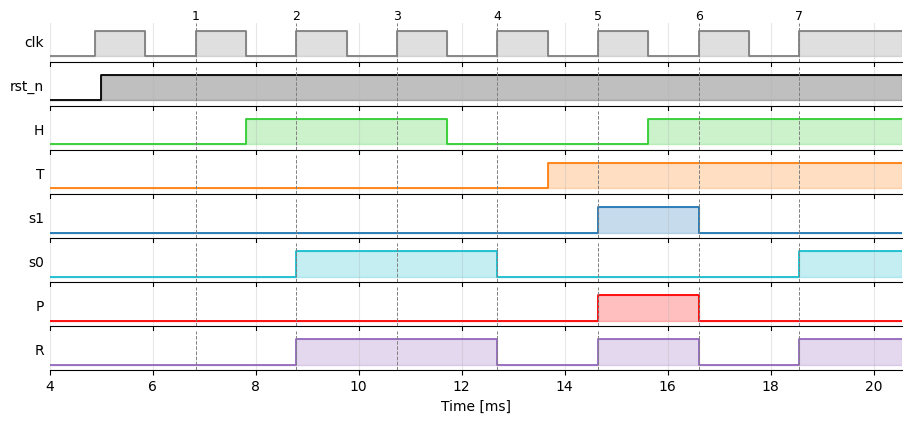

In [3]:
fsm = read_vcd("tb_fsm.vcd")
print(fsm.keys())

fsm["H"] = fsm["h"]
fsm["P"] = fsm["p"]
fsm["T"] = (fsm["tn"][0], 1 - fsm["tn"][1])   # T  = NOT tn
fsm["R"] = (fsm["rn"][0], 1 - fsm["rn"][1])   # R  = NOT rn

rst   = rising_edges(fsm, "rst_n")[0]
edges = rising_edges(fsm, "clk", after=rst)[:7]
plot_digital(fsm, ["clk", "rst_n", "H", "T", "s1", "s0", "P", "R"],
             rst - 1e-3, edges[-1] + 2e-3, ms=True, figsize=(11, 4.5),
             marks=[(e, str(i + 1)) for i, e in enumerate(edges)])

lese tb pacemaker:  

dict_keys(['P', 's1', 's0', 'T', 'clk', 'H', 'rst_n'])


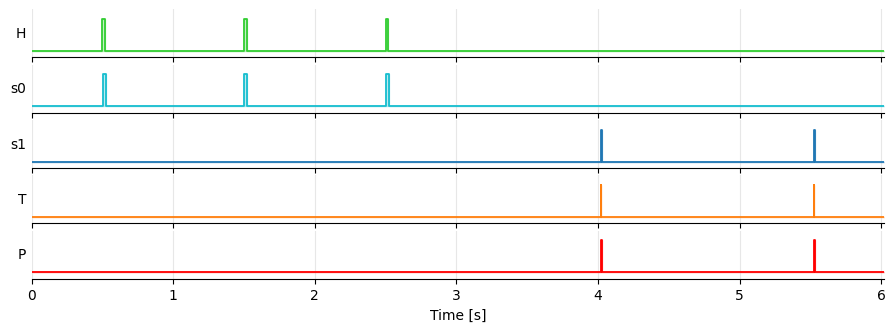

In [4]:
pm = read_vcd("tb_pacemaker.vcd")
print(pm.keys())

plot_digital(pm, ["H", "s0", "s1", "T", "P"], 0, 6.02)

zoom inn på første pacing for pacemaker

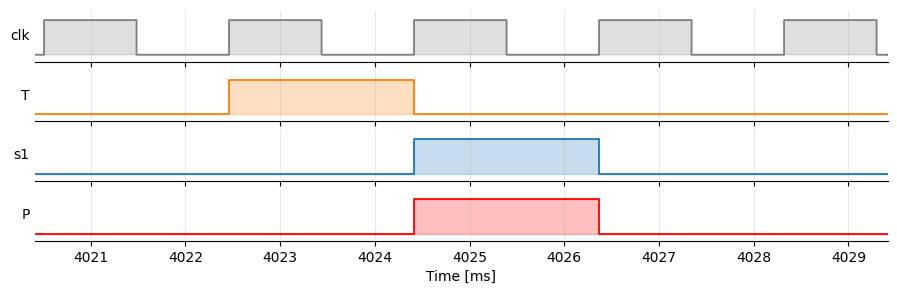

In [5]:
p_rise = rising_edges(pm, "P")[0]
plot_digital(pm, ["clk", "T", "s1", "P"], p_rise - 4e-3, p_rise + 5e-3,
             ms=True, figsize=(11, 3))